In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Trainer import Trainer
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [2]:
# nr_genes_list = [32, 64, 128]
from halcyon.Simulators.GNWSimRunner import SimulationResult

nr_genes_list = [15]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [3]
sparsity_list = [0.05]
out_path = Path("../data/hybrid_model_first_tests") 

sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False
            )
            sim_outputs.append(sim_output) 
sim_outputs

2025-11-12 14:30:16,294 - INFO - Generating network
2025-11-12 14:30:17,187 - INFO - Simulating network expression over time


[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05'), network_name='my_network', nr_genes=15, nr_modules=3, sparsity=0.05, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7fa7346ef340>)]

In [3]:
sim_output = sim_outputs[0]

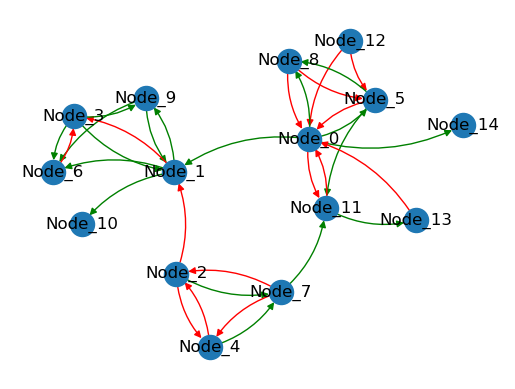

In [4]:
sim_output.network.plot()
plt.show()

In [5]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml', condition_names=(), from_gnw=True)
# Select only genes from specific module: here Nodes: 0, 11, 5, 8
mm.select_genes([f'Node_{i}' for i in [0, 11, 5, 8]])
# Fit MM on this data (skip for now?)
mm.modelled_gene_labels

2025-11-12 14:30:23,558 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/my_network.xml
2025-11-12 14:30:25,305 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-12 14:30:25,312 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-12 14:30:25,313 - INFO - Using CPU instead.


['Node_0', 'Node_11', 'Node_5', 'Node_8']

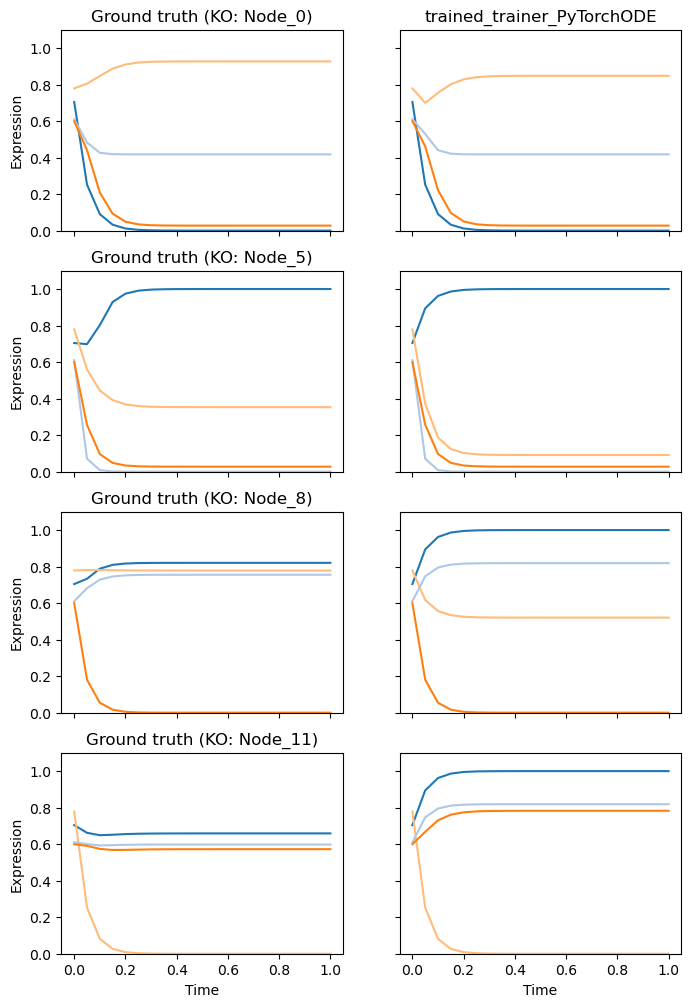

In [6]:
# Training MM
mm_trainer = Trainer(
    mm,
    sim_output,
    batch_size=32,
    nr_training_steps=1,
    # optimizer_fn=lambda x: None
)

only_mm_list = FittedTrainerList([mm_trainer])
only_mm_list.plot_all_model_fits_into_one_fig();plt.show()

mm_trainer.save(mm_trainer.save_path)

In [7]:
expr_data = sim_output.get_no_noise_ko_timeseries_expressiondata()
expr_data.genes

['Node_0',
 'Node_1',
 'Node_2',
 'Node_3',
 'Node_4',
 'Node_5',
 'Node_6',
 'Node_7',
 'Node_8',
 'Node_9',
 'Node_10',
 'Node_11',
 'Node_12',
 'Node_13',
 'Node_14']

In [8]:
# Create ML
ml = PhoenixAddAndProdLayers(
        modelled_gene_labels=expr_data.genes,
        hidden_size=4,
        condition_names=expr_data.all_environments,
)

# Create hybrid model with MM and cellbox with add and prod
hybrid_model = HybridModel(mm, ml)

# my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
# Train it on the single ko data
hybrid_trainer = Trainer(
    hybrid_model,
    sim_output,
    batch_size=32,
    nr_training_steps=2
)

2025-11-12 14:31:11,845 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-12 14:31:11,847 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-12 14:31:11,850 - INFO - Using CPU instead.
2025-11-12 14:31:11,853 - WARNING - GPU NVIDIA L40S (compute capability 8.9) is not compatible.
2025-11-12 14:31:11,854 - INFO - Supported architectures: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120', 'compute_120']
2025-11-12 14:31:11,855 - INFO - Using CPU instead.


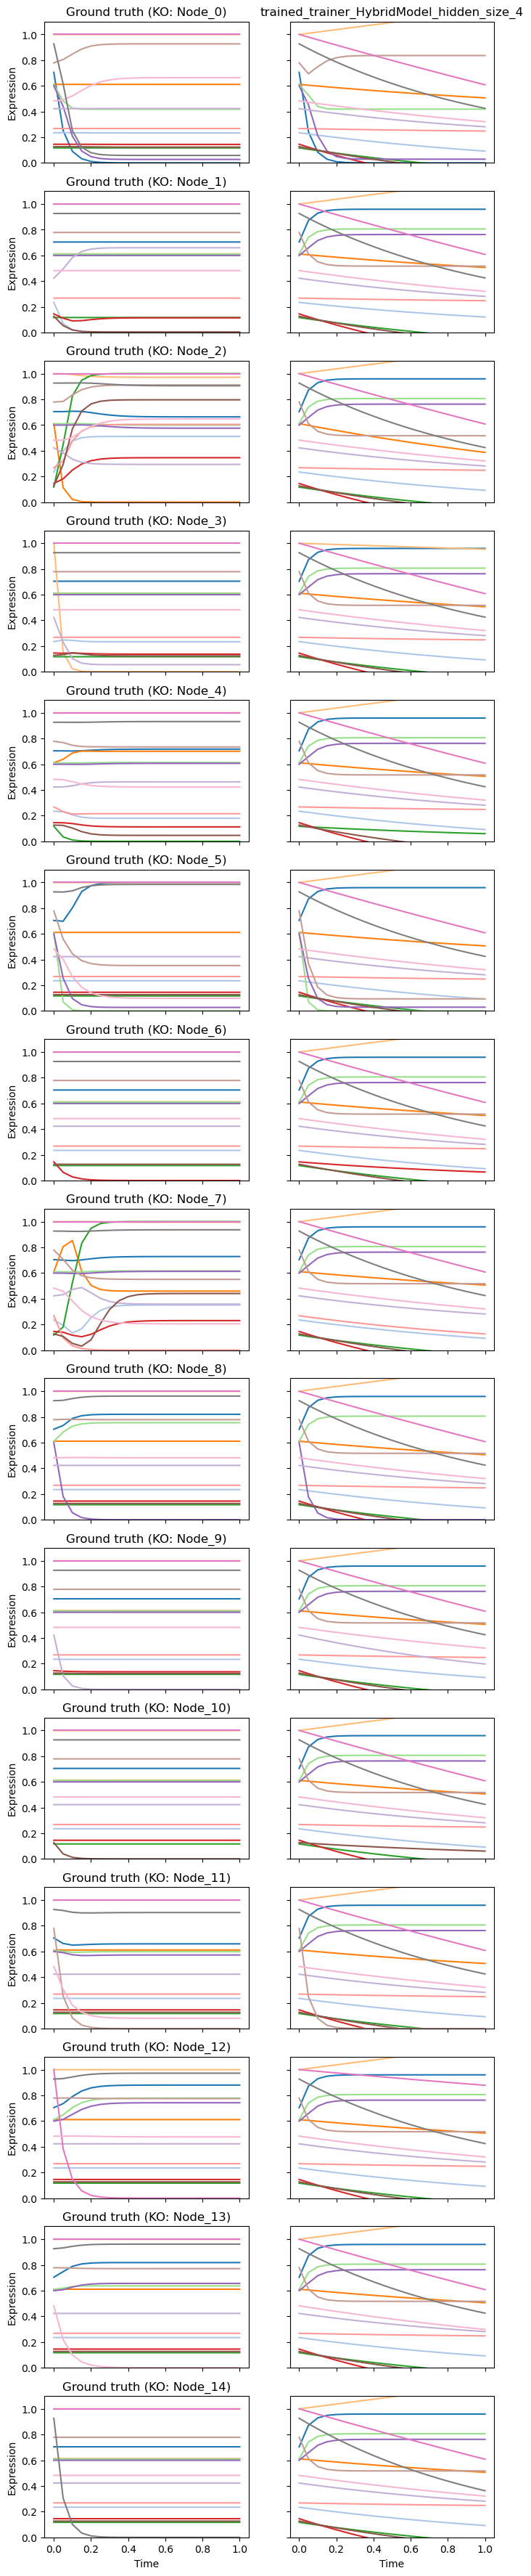

In [9]:
only_hybrid_list = FittedTrainerList([hybrid_trainer])
only_hybrid_list.plot_all_model_fits_into_one_fig();plt.show()

In [11]:
hybrid_trainer.save(hybrid_trainer.save_path)

In [ ]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=8) as pool:
    pool.map(run_training_job, train_jobs)

In [12]:
result_list = FittedTrainerList.from_train_jobs([mm_trainer, hybrid_trainer])

2025-11-12 14:32:34,000 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/trained_trainer_PyTorchODE.pt
2025-11-12 14:32:34,044 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_15_modules_3_sparsity_0.05/trained_trainer_HybridModel_hidden_size_4.pt


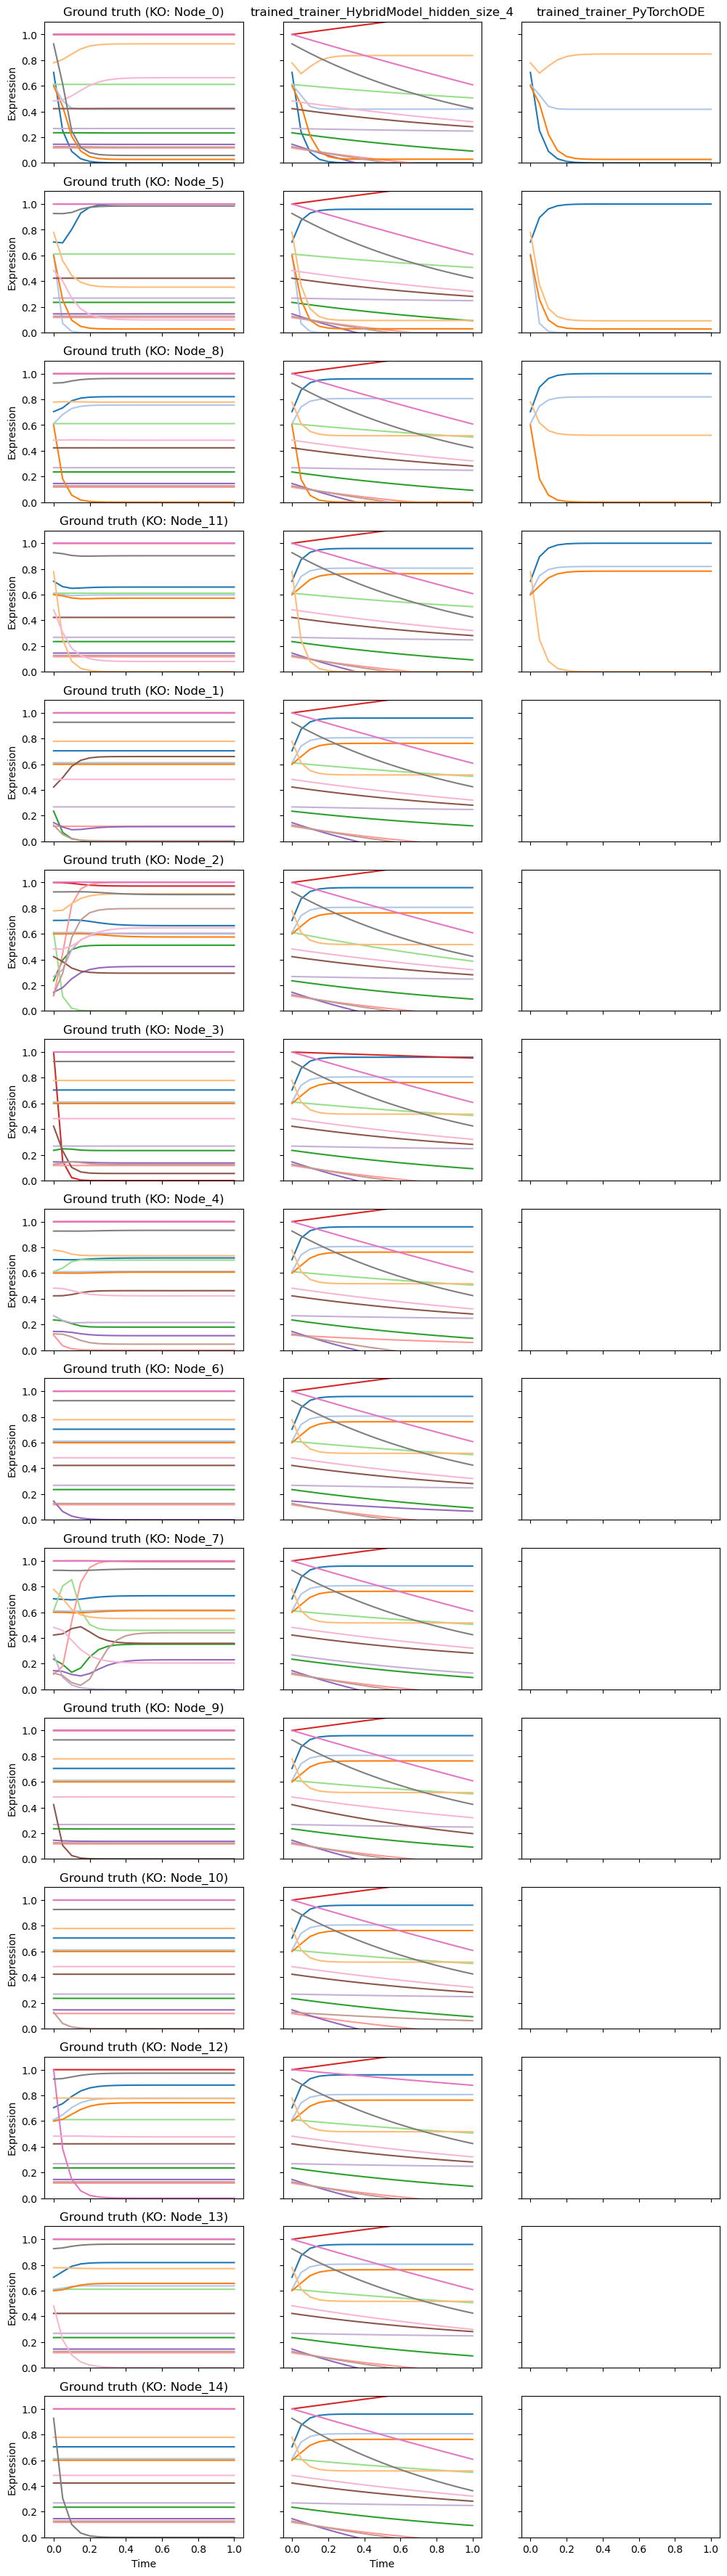

In [13]:
result_list.plot_all_model_fits_into_one_fig(); plt.show()

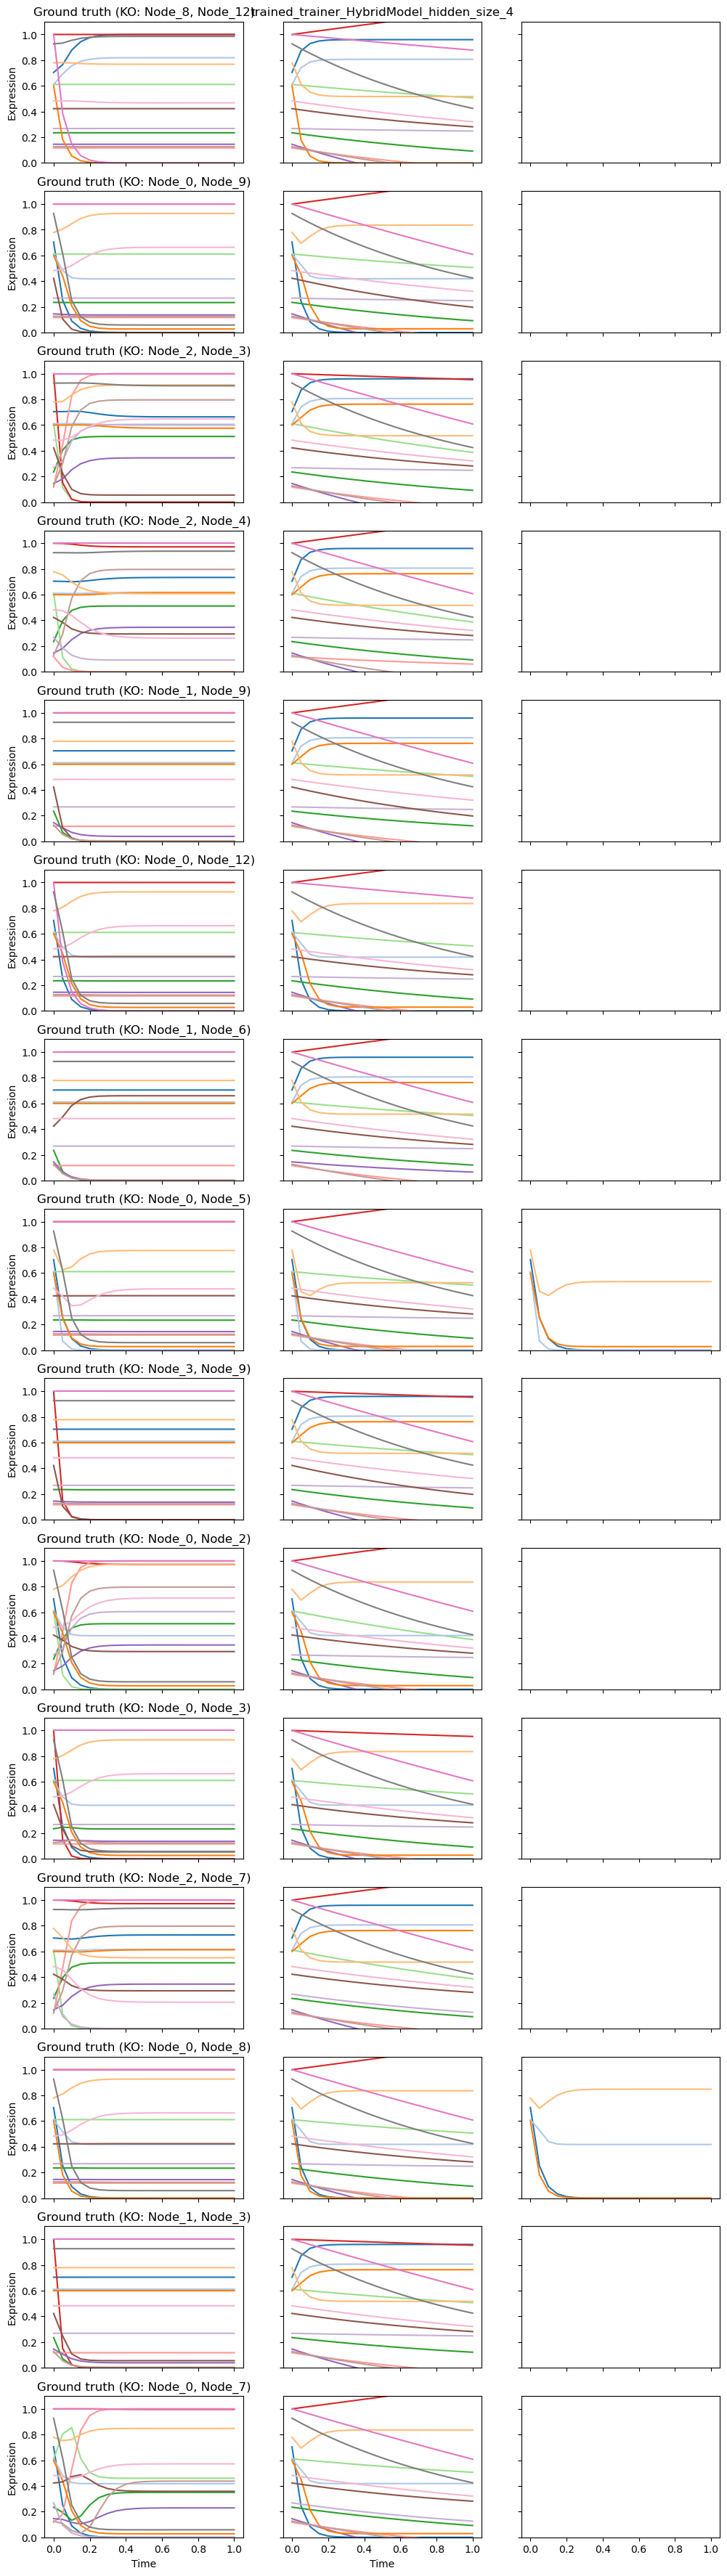

In [14]:
result_list.plot_all_model_fits_into_one_fig(only_double_ko=True);plt.show()